# Table 1 | Snow depth performance

Publication revision of [Table 1](inreview/table1.ipynb). Both lapse-rate forcing configurations use the same soil simulations as Figure 4. The water years, 5 cm snow threshold, and review metrics are retained.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

model_root = Path('/home/cassie/python/models/run_snowpack/sites')
data_root = Path('/hdd/snow_hydrology')

# Display name, water-year range, mixed forcing file span, station file.
sites = {
    'ppsa': ('Powder Patch Meteorological Station (PPSA)', 2023, 2025, 'WY2020-WY2025',
             'ppsa2/pppsa_met_station_data_synoptic_2026-03-20'),
    'tram': ('Mount Roberts Tramway Meteorological Station (TRAM)', 2023, 2025, 'WY2023-WY2025',
             'tram/tram_met_station_data_synoptic_2026-03-20'),
    'heen': ('Heen Latinee SNOTEL (HEEN)', 2020, 2022, 'WY2020-WY2022',
             'snotel/heenlatinee/heen_met_2016_2026_cleaned_v1.nc'),
}

In [2]:
def read_snow_depth(path):
    header = {}
    with path.open() as source:
        for line in source:
            if line.strip() == '[DATA]':
                break
            if '=' in line:
                key, value = line.split('=', 1)
                header[key.strip()] = value.strip()
        else:
            raise ValueError(f'Missing [DATA] section in {path}')
        fields = header['fields'].split()
        data = pd.read_csv(source, sep=r'\s+', names=fields,
                           usecols=['timestamp', 'HS_mod'], index_col='timestamp',
                           parse_dates=['timestamp'], na_values=float(header['nodata']))
    if data.empty or not data.index.is_unique or not data.index.is_monotonic_increasing:
        raise ValueError(f'Expected a nonempty, ordered snow depth series in {path}')
    # SMET's multiplier converts the stored value to meters. Plot centimeters.
    multiplier = float(header['units_multiplier'].split()[fields.index('HS_mod')])
    return data['HS_mod'] * multiplier * 100


observations = {}
simulations = {}
for site, (_, _, _, mixed_span, filename) in sites.items():
    with xr.open_dataset(data_root / 'met_station' / filename) as ds:
        observations[site] = ds['hs'].load()
    for forcing, span in (('hrrrak_lapserate', 'WY2020-WY2025'),
                          ('met_hrrrak_lapserate', mixed_span)):
        path = model_root / site / 'output' / f'{forcing}_{site}_{span}_soil.smet'
        simulations[forcing, site] = read_snow_depth(path).rename_axis('time').to_xarray()

In [3]:
import numpy as np
import pandas as pd
import xarray as xr

# ============================================================
# USER SETTINGS
# ============================================================

snow_threshold_cm = 5.0

# Water years to evaluate by site
site_water_years = {
    "PPSA": [2023, 2024, 2025],
    "TRAM": [2023, 2024, 2025],
    "HEEN": [2020, 2021, 2022],
}

# ============================================================
# Helper functions
# ============================================================

def water_year_slice(da, wy):
    """
    Select one water year.
    WY2025 = 2024-10-01 through 2025-09-30.
    """
    start = f"{wy-1}-10-01"
    end = f"{wy}-09-30 23:59:59"
    return da.sel(time=slice(start, end))


def align_model_obs(model_da, obs_da):
    """
    Align model and observation data on common valid timestamps.
    """
    model_df = model_da.to_dataframe(name="model")
    obs_df = obs_da.to_dataframe(name="obs")

    df = pd.concat([model_df, obs_df], axis=1).dropna()

    return df


def calculate_rmse(model, obs):
    return np.sqrt(np.nanmean((model - obs) ** 2))


def calculate_bias(model, obs):
    return np.nanmean(model - obs)


def calculate_peak_snow_depth_error(model, obs):
    return np.nanmax(model) - np.nanmax(obs)


def get_peak_snow_date(series):
    """
    Return date of maximum snow depth.
    """
    if series.dropna().empty:
        return pd.NaT

    return series.idxmax()


def get_snow_disappearance_date(series, threshold=5.0):
    """
    Snow disappearance is defined as the last timestamp in the water year
    when snow depth is greater than or equal to the threshold.

    This avoids false melt-out during temporary mid-winter melt periods.
    """
    snow_present = series >= threshold

    if not snow_present.any():
        return pd.NaT

    return series.index[snow_present][-1]


def get_ablation_duration_days(series, threshold=5.0):
    """
    Ablation duration is the time from peak snow depth to snow disappearance.
    """
    peak_date = get_peak_snow_date(series)
    disappearance_date = get_snow_disappearance_date(series, threshold)

    if pd.isna(peak_date) or pd.isna(disappearance_date):
        return np.nan

    return (disappearance_date - peak_date).days


def safe_date_error(model_date, obs_date):
    """
    Difference between modeled and observed dates in days.
    Positive = modeled event occurs later.
    Negative = modeled event occurs earlier.
    """
    if pd.isna(model_date) or pd.isna(obs_date):
        return np.nan

    return (model_date - obs_date).days


# ============================================================
# Compute statistics for one site/model/water year
# ============================================================

def compute_snowpack_statistics_by_wy(
    model_da,
    obs_da,
    model_name,
    site_name,
    wy,
    threshold=5.0
):
    # --------------------------------------------------------
    # Slice to water year
    # --------------------------------------------------------

    model_wy = water_year_slice(model_da, wy)
    obs_wy = water_year_slice(obs_da, wy)

    # --------------------------------------------------------
    # Align model and observations
    # --------------------------------------------------------

    df = align_model_obs(model_wy, obs_wy)

    if df.empty:
        return {
            "Site": site_name,
            "Water Year": f"WY{wy}",
            "Model": model_name,
            "RMSE (cm)": np.nan,
            "Bias (cm)": np.nan,
            "Peak Snow Depth Error (cm)": np.nan,
            "Snow Disappearance Error (days)": np.nan,
            "Ablation Duration Error (days)": np.nan,
            "Observed Peak Snow Depth (cm)": np.nan,
            "Modeled Peak Snow Depth (cm)": np.nan,
        }

    model = df["model"]
    obs = df["obs"]

    # --------------------------------------------------------
    # Magnitude metrics
    # --------------------------------------------------------

    rmse = calculate_rmse(model, obs)
    bias = calculate_bias(model, obs)
    peak_error = calculate_peak_snow_depth_error(model, obs)

    # --------------------------------------------------------
    # Timing metrics
    # --------------------------------------------------------

    model_disappearance = get_snow_disappearance_date(
        model,
        threshold=threshold
    )

    obs_disappearance = get_snow_disappearance_date(
        obs,
        threshold=threshold
    )

    disappearance_error = safe_date_error(
        model_disappearance,
        obs_disappearance
    )

    model_ablation_duration = get_ablation_duration_days(
        model,
        threshold=threshold
    )

    obs_ablation_duration = get_ablation_duration_days(
        obs,
        threshold=threshold
    )

    ablation_duration_error = (
        model_ablation_duration - obs_ablation_duration
    )

    # --------------------------------------------------------
    # Build result
    # --------------------------------------------------------

    return {
        "Site": site_name,
        "Water Year": f"WY{wy}",
        "Model": model_name,

        "RMSE (cm)": rmse,
        "Bias (cm)": bias,
        "Peak Snow Depth Error (cm)": peak_error,
        "Snow Disappearance Error (days)": disappearance_error,
        "Ablation Duration Error (days)": ablation_duration_error,

        "Observed Peak Snow Depth (cm)": np.nanmax(obs),
        "Modeled Peak Snow Depth (cm)": np.nanmax(model),
    }


# ============================================================
# Build list of FINAL manuscript comparisons
# ============================================================

comparisons = [

    # PPSA
    {
        "site": "PPSA",
        "model_name": "HRRR-AK Forcing",
        "model": simulations['hrrrak_lapserate', 'ppsa'],
        "obs": observations['ppsa'],
    },
    {
        "site": "PPSA",
        "model_name": "Met Station Mixed Forcing",
        "model": simulations['met_hrrrak_lapserate', 'ppsa'],
        "obs": observations['ppsa'],
    },

    # TRAM
    {
        "site": "TRAM",
        "model_name": "HRRR-AK Forcing",
        "model": simulations['hrrrak_lapserate', 'tram'],
        "obs": observations['tram'],
    },
    {
        "site": "TRAM",
        "model_name": "Met Station Mixed Forcing",
        "model": simulations['met_hrrrak_lapserate', 'tram'],
        "obs": observations['tram'],
    },

    # HEEN
    {
        "site": "HEEN",
        "model_name": "HRRR-AK Forcing",
        "model": simulations['hrrrak_lapserate', 'heen'],
        "obs": observations['heen'],
    },
    {
        "site": "HEEN",
        "model_name": "Met Station Mixed Forcing",
        "model": simulations['met_hrrrak_lapserate', 'heen'],
        "obs": observations['heen'],
    },
]


# ============================================================
# Calculate yearly statistics
# ============================================================

results = []

for comparison in comparisons:

    site = comparison["site"]

    for wy in site_water_years[site]:

        stats = compute_snowpack_statistics_by_wy(
            model_da=comparison["model"],
            obs_da=comparison["obs"],
            model_name=comparison["model_name"],
            site_name=site,
            wy=wy,
            threshold=snow_threshold_cm,
        )

        results.append(stats)

df_yearly = pd.DataFrame(results)

# ============================================================
# Add average rows for each Site / Model
# ============================================================

metric_cols = [
    "RMSE (cm)",
    "Bias (cm)",
    "Peak Snow Depth Error (cm)",
    "Snow Disappearance Error (days)",
    "Ablation Duration Error (days)",
    "Observed Peak Snow Depth (cm)",
    "Modeled Peak Snow Depth (cm)",
]

df_avg = (
    df_yearly
    .groupby(["Site", "Model"], as_index=False)[metric_cols]
    .mean()
)

df_avg["Water Year"] = "Average"

# Match column order
df_avg = df_avg[df_yearly.columns]

# Combine yearly and average rows
df_results = pd.concat(
    [df_yearly, df_avg],
    ignore_index=True
)

# ============================================================
# Sort table in desired order
# ============================================================

site_order = ["PPSA", "TRAM", "HEEN"]

model_order = [
    "HRRR-AK Forcing",
    "Met Station Mixed Forcing",
]

wy_order = {
    "WY2020": 2020,
    "WY2021": 2021,
    "WY2022": 2022,
    "WY2023": 2023,
    "WY2024": 2024,
    "WY2025": 2025,
    "Average": 9999,
}

df_results["Site_order"] = df_results["Site"].map(
    {site: i for i, site in enumerate(site_order)}
)

df_results["Model_order"] = df_results["Model"].map(
    {model: i for i, model in enumerate(model_order)}
)

df_results["WY_order"] = df_results["Water Year"].map(wy_order)

df_results = (
    df_results
    .sort_values(["Site_order", "WY_order", "Model_order"])
    .drop(columns=["Site_order", "Model_order", "WY_order"])
    .reset_index(drop=True)
)

# ============================================================
# Format output precision
# ============================================================

# USER SETTING:
# Change this to 1 or 2 depending on preferred displayed precision
sig_figs = 2

def round_sig(x, sig=2):
    """
    Round to a specified number of significant figures.
    Keeps NaN values as NaN.
    """
    if pd.isna(x):
        return np.nan
    if x == 0:
        return 0
    return round(x, sig - int(np.floor(np.log10(abs(x)))) - 1)


sig_fig_cols = [
    "RMSE (cm)",
    "Bias (cm)",
    "Peak Snow Depth Error (cm)",
    "Observed Peak Snow Depth (cm)",
    "Modeled Peak Snow Depth (cm)",
]

df_results[sig_fig_cols] = df_results[sig_fig_cols].map(
    lambda x: round_sig(x, sig=sig_figs)
)

day_cols = [
    "Snow Disappearance Error (days)",
    "Ablation Duration Error (days)",
]

# Keep day errors as whole days
df_results[day_cols] = df_results[day_cols].round(0)

df_table1_average = df_results.loc[df_results['Water Year'] == 'Average'].copy()
df_supplement_yearly = df_results.loc[df_results['Water Year'] != 'Average'].copy()


## Manuscript summary

Each row averages three water years. Positive errors indicate higher modeled
snow depth, later modeled melt-out, or longer modeled ablation.

In [4]:
# ============================================================
# TABLE 1 FOR MANUSCRIPT
# Final forcing configurations only
# ============================================================

table1 = df_table1_average[
    [
        "Site",
        "Model",
        "RMSE (cm)",
        "Bias (cm)",
        "Peak Snow Depth Error (cm)",
        "Snow Disappearance Error (days)",
        "Ablation Duration Error (days)",
    ]
].copy()

# Round manuscript values
table1 = table1.round(
    {
        "RMSE (cm)": 0,
        "Bias (cm)": 0,
        "Peak Snow Depth Error (cm)": 0,
        "Snow Disappearance Error (days)": 0,
        "Ablation Duration Error (days)": 0,
    }
)

short_headers = {
    'Peak Snow Depth Error (cm)': 'Peak depth error (cm)',
    'Snow Disappearance Error (days)': 'Melt-out error (days)',
    'Ablation Duration Error (days)': 'Ablation duration error (days)',
    'Observed Peak Snow Depth (cm)': 'Observed peak (cm)',
    'Modeled Peak Snow Depth (cm)': 'Modeled peak (cm)',
}

def style_performance(frame, caption):
    numeric = frame.select_dtypes(include='number').columns
    return (
        frame.style.hide(axis='index').set_caption(caption)
        .format({col: '{:g}' for col in numeric}, na_rep='—')
        .set_properties(subset=numeric, **{'text-align': 'right'})
        .set_table_styles([
            {'selector': 'caption', 'props': [('text-align', 'left'), ('font-weight', 'bold')]},
            {'selector': 'th', 'props': [('text-align', 'left'), ('white-space', 'normal')]},
            {'selector': 'th, td', 'props': [('padding', '5px 8px')]},
        ])
    )

display(style_performance(table1.rename(columns=short_headers), 'Table 1. Mean snow depth performance'))


Site,Model,RMSE (cm),Bias (cm),Peak depth error (cm),Melt-out error (days),Ablation duration error (days)
PPSA,HRRR-AK Forcing,34,25,37,6,18
PPSA,Met Station Mixed Forcing,26,13,19,4,4
TRAM,HRRR-AK Forcing,28,15,52,5,-5
TRAM,Met Station Mixed Forcing,31,-18,-33,-8,9
HEEN,HRRR-AK Forcing,46,29,51,22,17
HEEN,Met Station Mixed Forcing,41,24,56,19,53


## Year-by-year results

In [5]:
for site, yearly in df_supplement_yearly.groupby('Site', sort=False):
    yearly = yearly.drop(columns='Site').rename(columns=short_headers)
    display(style_performance(yearly, f'{site} | Snow depth performance by water year'))

Water Year,Model,RMSE (cm),Bias (cm),Peak depth error (cm),Melt-out error (days),Ablation duration error (days),Observed peak (cm),Modeled peak (cm)
WY2023,HRRR-AK Forcing,45,39,45,7,16,340,390
WY2023,Met Station Mixed Forcing,35,30,47,7,8,340,390
WY2024,HRRR-AK Forcing,28,17,1.3,12,11,270,270
WY2024,Met Station Mixed Forcing,23,-7.6,-32,4,3,270,240
WY2025,HRRR-AK Forcing,30,20,65,-2,27,180,250
WY2025,Met Station Mixed Forcing,22,16,42,1,2,180,220


Water Year,Model,RMSE (cm),Bias (cm),Peak depth error (cm),Melt-out error (days),Ablation duration error (days),Observed peak (cm),Modeled peak (cm)
WY2023,HRRR-AK Forcing,48,38,82,10,-10,300,380
WY2023,Met Station Mixed Forcing,25,-11,-29,-3,-23,300,270
WY2024,HRRR-AK Forcing,21,3,17,9,5,260,270
WY2024,Met Station Mixed Forcing,40,-25,-54,-1,75,260,200
WY2025,HRRR-AK Forcing,16,4.1,56,-4,-9,120,180
WY2025,Met Station Mixed Forcing,26,-17,-16,-19,-24,120,110


Water Year,Model,RMSE (cm),Bias (cm),Peak depth error (cm),Melt-out error (days),Ablation duration error (days),Observed peak (cm),Modeled peak (cm)
WY2020,HRRR-AK Forcing,39,22,33,24,24,220,250
WY2020,Met Station Mixed Forcing,64,43,89,24,17,220,310
WY2021,HRRR-AK Forcing,38,23,54,15,15,240,290
WY2021,Met Station Mixed Forcing,31,16,43,16,75,240,280
WY2022,HRRR-AK Forcing,62,42,66,26,11,250,310
WY2022,Met Station Mixed Forcing,29,12,37,17,66,250,290


## Modeled minus observed snow depth

The bars visualize the three-water-year averages reported in Table 1. Mean bias compares snow depth at matched timestamps. Peak depth error compares the modeled and observed seasonal maxima. Negative values indicate shallower modeled snow.

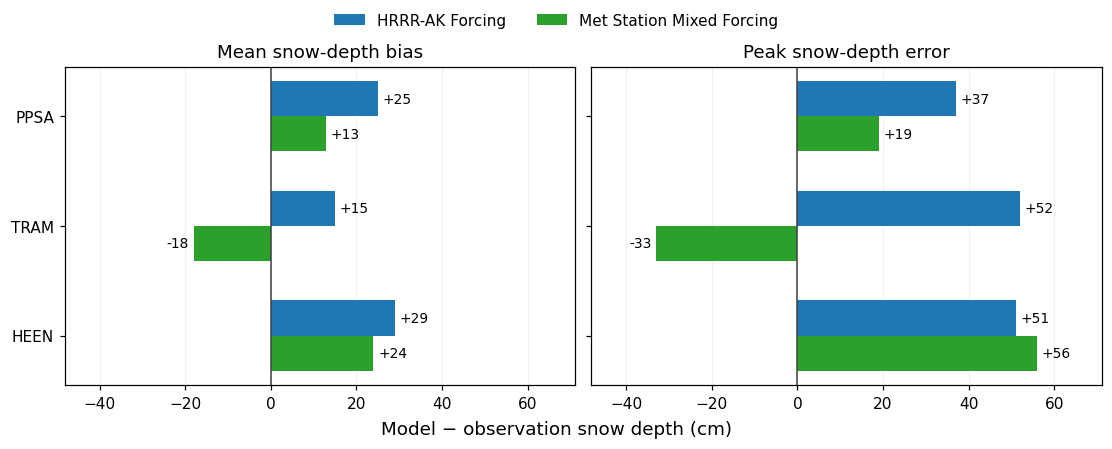

In [6]:
import matplotlib.pyplot as plt

forcing_colors = {
    "HRRR-AK Forcing": "tab:blue",
    "Met Station Mixed Forcing": "tab:green",
}


def plot_performance_metrics(metrics, xlabel, *, signed=True):
    fig, axes = plt.subplots(
        1, len(metrics), figsize=(5 * len(metrics), 4), sharex=True, sharey=True,
        squeeze=False, layout="constrained",
    )
    positions = np.arange(len(site_order))
    bar_height = .32
    for ax, (metric, title) in zip(axes.flat, metrics.items()):
        for offset, model in zip((-bar_height / 2, bar_height / 2), model_order):
            values = (table1.loc[table1["Model"].eq(model)]
                      .set_index("Site")[metric].reindex(site_order))
            bars = ax.barh(positions + offset, values, height=bar_height,
                           color=forcing_colors[model], label=model)
            number_format = "+.0f" if signed else ".0f"
            ax.bar_label(bars, labels=[format(value, number_format) if np.isfinite(value) else ""
                                       for value in values], padding=3, fontsize=9)
        ax.set_title(title)
        ax.set_yticks(positions, site_order)
        ax.axvline(0, color="0.25", linewidth=1)
        ax.grid(axis="x", alpha=.2)
        ax.set_axisbelow(True)
        ax.margins(x=.17)

    axes[0, 0].invert_yaxis()
    if not signed:
        axes[0, 0].set_xlim(left=0)
    fig.supxlabel(xlabel)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside upper center", ncol=2, frameon=False)
    plt.show()


plot_performance_metrics(
    {"Bias (cm)": "Mean snow-depth bias", "Peak Snow Depth Error (cm)": "Peak snow-depth error"},
    "Model − observation snow depth (cm)",
)

## Melt-out and ablation timing

Positive errors indicate later modeled melt-out or a longer modeled ablation period.

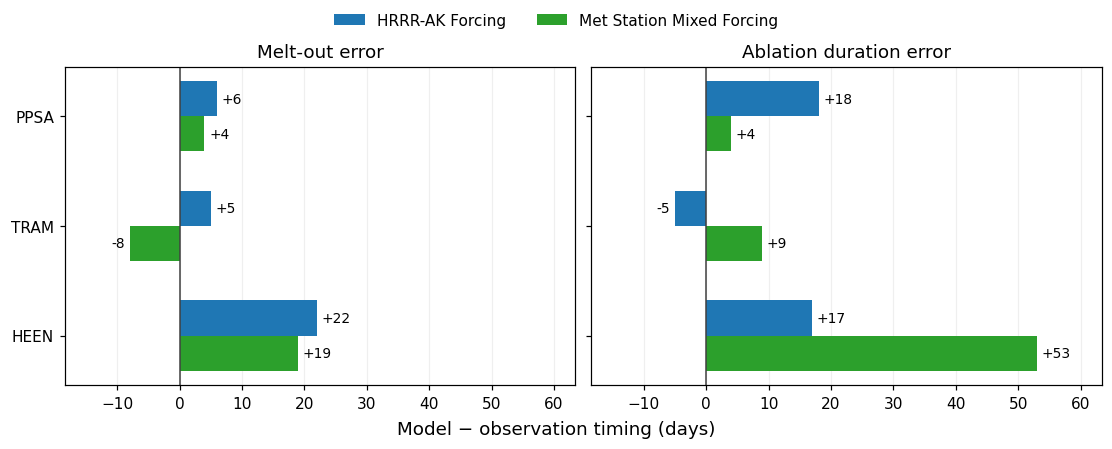

In [7]:
plot_performance_metrics(
    {"Snow Disappearance Error (days)": "Melt-out error",
     "Ablation Duration Error (days)": "Ablation duration error"},
    "Model − observation timing (days)",
)

## Snow-depth RMSE

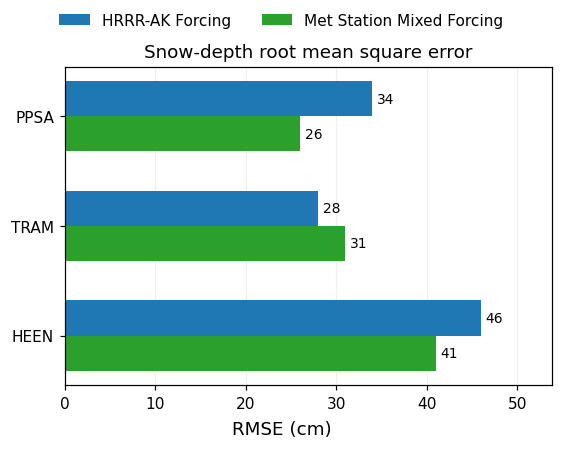

In [8]:
plot_performance_metrics(
    {"RMSE (cm)": "Snow-depth root mean square error"},
    "RMSE (cm)", signed=False,
)